# AI4GSD Demo
------------------------------------------
## Smartphone videos
------------------------------------------
#### Table of contents
#### 0. Installing requried packages
#### 1. Importing required packages
#### 2. Defining working directory
#### 3. Extracting or copying your videos/photos to desired folder
#### 4. Obtaining scales from AI, drone flight data, or manual measurements
#### 5. Obtaining segmentation of anthropogenic objects
#### 6. Obtaining grain size data
#### 7. Applying quality control

##### *** Please contact Yunxiang Chen, yunxiang.chen@pnnl.gov for reporting errors

------------------------------------------
### 0. Installing requried packages

#### 0a. Downloading AI4GSD data from GitHub

In [ ]:
from pathlib import Path
import sys, subprocess
WorkDir = Path("/content/AI4GSD")
if not WorkDir.exists(): subprocess.run(["git", "clone", "--progress", "https://github.com/pnnl/AI4GSD.git", str(WorkDir)],check=True)

### 0b. Install requried packages

In [ ]:
%pip install -q numpy==2.2.6 pandas==2.2.3 matplotlib==3.10.6 opencv-python==4.12.0.88
%pip install -q torch torchvision ultralytics==8.3.186
%pip install -q natsort pyproj PyExifTool piexif imutils shapely psutil

### 0c. Define Google drive parement path and add it to system.

In [ ]:
sys.path.insert(0, str(WorkDir))
print([item.name for item in WorkDir.iterdir()])

['.gitignore', 'AI4GSD', 'Demo_JupyterNotebook', 'Disclaimer Notice.txt', '.gitattributes', 'Install.md', '.git', 'Demo_Data', 'Demo_Python_Release', 'Licenses', 'Scales', 'README.md']


### 1. Importing required packages

In [ ]:
import AI4GSD

### 2. Defining working directory

In [ ]:
AI4GSD.pcinfo()
foldername = '20250521_YC_WalkSmartphoneRoadTest'                          # Parent folder where you save photos/videos.
PhotoDir = str(WorkDir / 'Demo_Data' / foldername)                         # AI4GSD use string path.

Machine name: PNNL-2MQ6330S2G
Operating system: Windows 11 Pro (build 26200)
Architecture: AMD64
Processor: Intel(R) Core(TM) Ultra 7 366H
Reported CPU frequency: 2.00 GHz


### 3. Extracting or copying your videos/photos to desired folder

In [ ]:
#%% (1) Extracting or copying your videos/photos to desired folder.
AI4GSD.getPhotos(PhotoDir,nframe=500, overwrite=False)                     # Use once.

Video photo output folder: D:\NG\AI4GSD\Demo_Data\20250521_YC_WalkSmartphoneRoadTest
Extracting IMG_9683.MOV every 500 frames.
IMG_9683.MOV: get frame 1 from 500/2171 in 0.00 s (23.03%), file existed, skipping...
IMG_9683.MOV: get frame 2 from 1000/2171 in 0.00 s (46.06%), file existed, skipping...
IMG_9683.MOV: get frame 3 from 1500/2171 in 0.00 s (69.09%), file existed, skipping...
IMG_9683.MOV: get frame 4 from 2000/2171 in 0.00 s (92.12%), file existed, skipping...

Computation done, elapsed time 0.44 seconds.




### 4. Obtaining scales from AI, drone flight data, or manual measurements

In [ ]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.OverWriteAll = True                                                     # Overwrite everything if True.
PP.OverWriteScaleFile = False
PP.OverWriteScaleRows = True
PP.ScaleSource = 'AI'                                                      # Use AI option.
PP.ModelName = 'YOLO11m.1280.20250825'                                     # Which AI to use.
PP.ComputingSource = 'local'                                               # What computing resource to use.
PP.ConfidenceThresholdUser = 0.85                                          # Minimum confidence threshold.
PP.YOLOSave = False                                                        # Need to save AI prediction to folder.
scales =  AI4GSD.metadata(PP)

Generating scale file for: 20250521_YC_WalkSmartphoneRoadTest
Estimating photo resolution via local AI model: YOLO11m.1280.20250825
Model layer: 113, model parmeter: 20.06M, submodule number: 409
IOU: 0.45, user confidence: 0.85
1/4: photo 1/4, IMG_9683_500.png, scale greencap, res 0.62 mm/px, status 200, (25.00%), 5.89 s
2/4: photo 2/4, IMG_9683_1000.png, scale greencap, res 0.59 mm/px, status 200, (50.00%), 1.46 s
3/4: photo 3/4, IMG_9683_1500.png, scale greencap, res 0.59 mm/px, status 200, (75.00%), 1.40 s
4/4: photo 4/4, IMG_9683_2000.png, scale greencap, res 0.65 mm/px, status 200, (100.00%), 1.44 s
Total time: 10.91 s, time per photo 2.73 s
-----------------------------------------------------------------



### 5. Obtaining segmentation of anthropogenic objects

In [ ]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.FolderLevel = 'L1'
PP.ModelName = 'YOLO11m.640.20250906'
PP.ObjectName = 'anthro'
PP.OverWriteSegementation = True
PP.YOLOSave = False
PP.YOLOIOU = 0.45
PP.ComputingSource = 'local'
PP.ImageSizeType = 'default'
PP.SegmentationClassName =['people','road','steel']                        # What object class need to track.
AI4GSD.background(PP)

-----------------------------------------------------------------
Folder name: 20250521_YC_WalkSmartphoneRoadTest
output name: segments
Model name: YOLO11m.640.20250906 from local for anthro
Model layer: 125, model parmeter: 22.37M, submodule number: 445
IOU: 0.45, user confidence: 0.35
Number of photos: 4, number of exluded photos 0
20250521_YC_WalkSmartphoneRoadTest: 1/4: IMG_9683_500.png (25.00%)
20250521_YC_WalkSmartphoneRoadTest: 2/4: IMG_9683_1000.png (50.00%)
20250521_YC_WalkSmartphoneRoadTest: 3/4: IMG_9683_1500.png (75.00%)
20250521_YC_WalkSmartphoneRoadTest: 4/4: IMG_9683_2000.png (100.00%)
Total time: 2.97 s, time per photo 0.74 s
-----------------------------------------------------------------



### 6. Obtaining grain size data

AI4GSD: an AI and cloud powered tool for grain size quantification
AI models in use: YOLO11m.1280.20250322
Confidence thresholds in use: 0.35

-----------------------------------------------------------------
Folder name: 20250521_YC_WalkSmartphoneRoadTest
Output folder: 20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35
Model name: YOLO11m.1280.20250322 from local for rock detection
Model layer: 113, model parmeter: 20.05M, submodule number: 409
IOU: 0.45, YOLO confidence: 0.25, user confidence: 0.35
Number of photos: 4, number of exluded photos 0
1/4: IMG_9683_500.png, resolution 0.62 mm/px (25.00%), 0.00 s
Detected 601 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.58, 4.14, 4.48, and 5.61 cm
Detected 601 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.34, 5.01, 5.35, and 6.41 cm


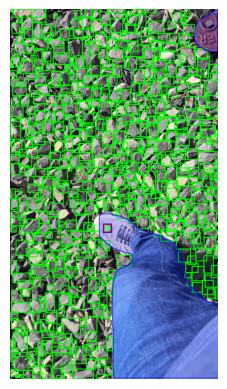

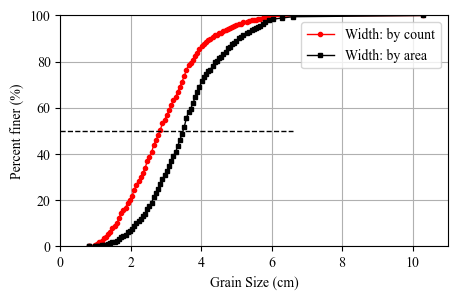

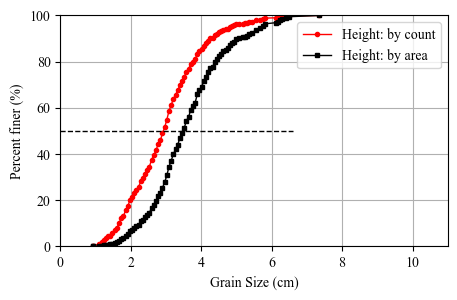

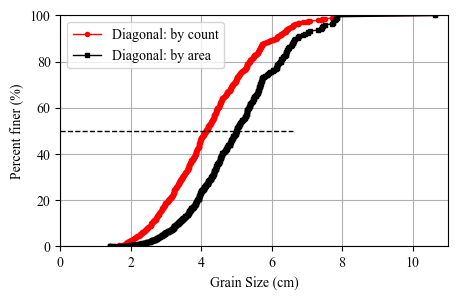

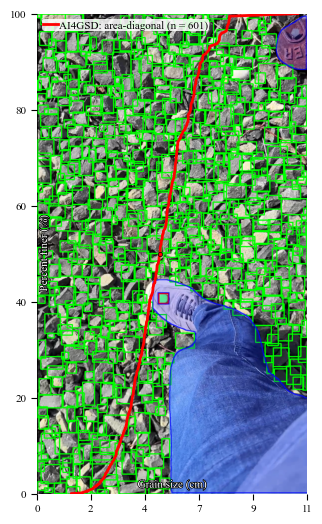

2/4: IMG_9683_1000.png, resolution 0.59 mm/px (50.00%), 6.46 s
Detected 639 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.12, 3.53, 3.82, and 4.75 cm
Detected 639 rocks, diagonal and area  based D10, D50, D60, and D84 are: 2.77, 4.32, 4.58, and 5.50 cm


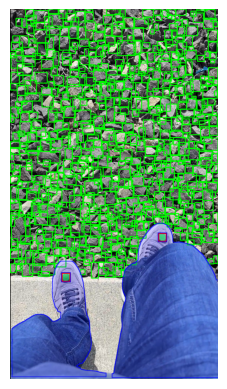

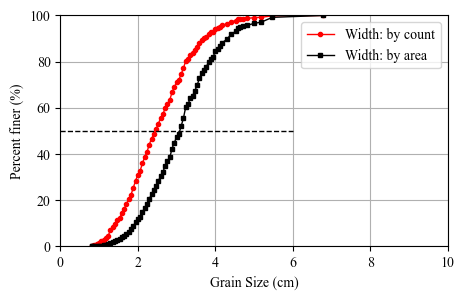

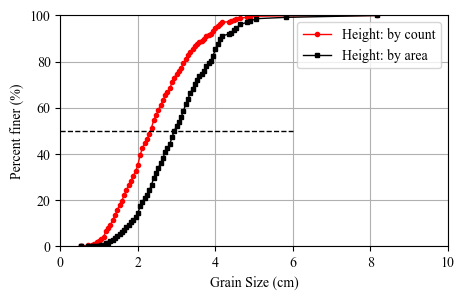

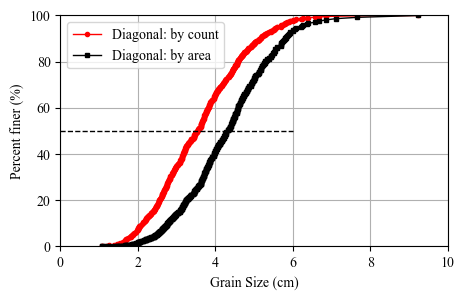

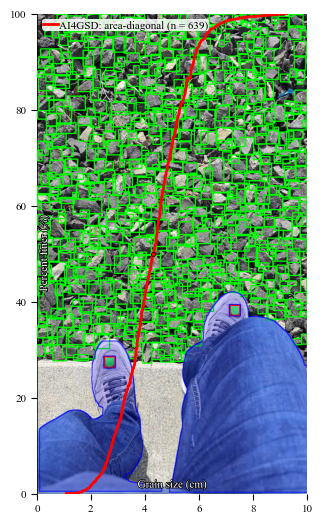

3/4: IMG_9683_1500.png, resolution 0.59 mm/px (75.00%), 6.08 s
Detected 628 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.21, 3.64, 3.97, and 4.83 cm
Detected 628 rocks, diagonal and area  based D10, D50, D60, and D84 are: 2.97, 4.39, 4.65, and 5.51 cm


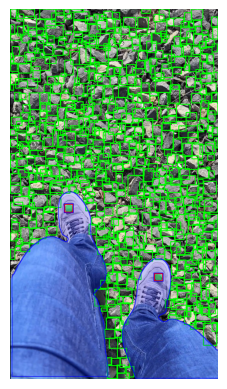

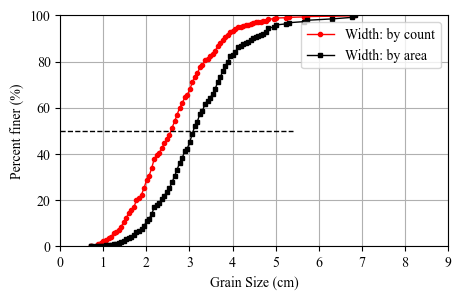

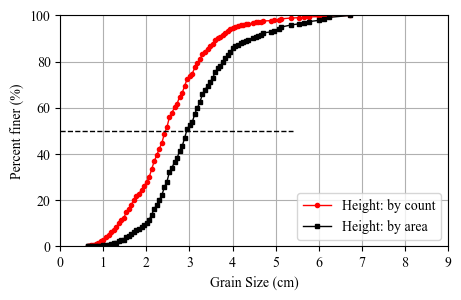

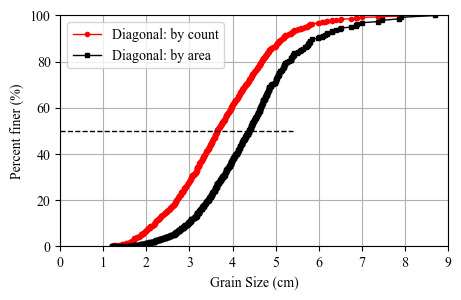

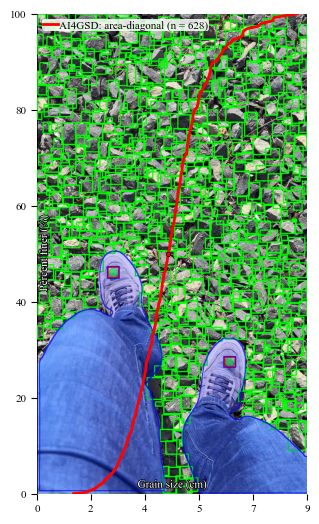

4/4: IMG_9683_2000.png, resolution 0.65 mm/px (100.00%), 6.06 s


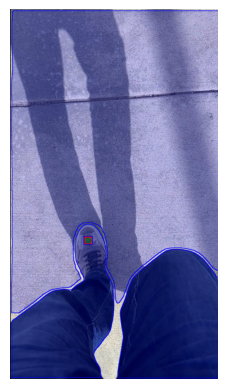

Output folder summary data to: D:\NG\AI4GSD\Demo_Data\20250521_YC_WalkSmartphoneRoadTest\grains_predicts\20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35\Statistics_V3_20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35.csv
Total number of grains: 1868, number of grains per photo: 467.00
Total time: 21.55 s, time per photo 5.39 s

Output all summary data to: D:\NG\AI4GSD\Demo_Data\20250521_YC_WalkSmartphoneRoadTest\Statistics_V3_20250521_YC_WalkSmartphoneRoadTest_YOLO11m.1280.20250322_35.csv
Total execution time: 21.56 s


In [ ]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.ModelName = 'YOLO11m.1280.20250322'
PP.YOLOSave = False
PP.SaveOverlayLabel = True
PP.OverWriteAll = True
PP.PrintOnScreen = True
PP.MaximumGrainSize = 0.15
PP.OverlayFontSize = 4
PP.OverlayLegendFontSize = 4
PP.OverlayGSDTickLineWidth = 4
gsd = AI4GSD.Photo2GSD(PP)

### 7. Applying quality control

In [ ]:
gsdqc, stqc = AI4GSD.qualityControl(PhotoDir)


Quality control summary for 20250521_YC_WalkSmartphoneRoadTest:
1/1: IMG_9683.MOV, time 36.2 s, area 3.1 m2, valid area 2.2 m2 (71.8%), frame 4, valid frame 3 (75.0%)
1/1: ***, grain number 1868, number per image 467.0; efficiency 0.1 m2/s, 51.6 grains/s
